# 01 — Validation: KDP (asymmetric GVM) and KTP (symmetric GVM / EPM)

Validation notebook for the `bibojsa` package, supporting the paper
*"Group-velocity-matched photon-pair generation in the monoclinic crystal
BiB3O6: joint spectral engineering and heralded-photon purity."*

Conventions (project brief / LPR2010): lambda1 >= lambda2 > lambda3 =
idler, signal, pump; o/e per principal plane; theta_PM =
arctan2(-(kp'-ks'), kp'-ki'). All dispersion derivatives are 4th-order
central finite differences with step-halving convergence checks.

Contents: Milestone 0 (BIBO Sellmeier vs LPR2010 Table 3), Milestone 1
(KDP, Mosley et al. PRL 100, 133601 (2008)), Milestone 2 (KTP, Konig &
Wong APL 84, 1644 (2004) [papers/09.] / Laudenbach et al. PRApplied 8,
024035 (2017)). The full pytest suite (62 tests) covers everything shown
here with hard assertions.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt

from bibojsa.materials.bibo import BIBO
from bibojsa.materials.kdp import KDP
from bibojsa.materials.ktp import KTP
from bibojsa.sellmeier import refractive_index, optic_axis_angle_deg, lambda_um_to_omega, C_LIGHT
from bibojsa.phasematch import ThreeWaveConfig, find_phase_matching_angle, find_qpm_period_um
from bibojsa.gvm import group_index_at_angle, theta_pm_deg, gvm_regime, phase_matched_group_delays_ps_per_mm
from bibojsa.jsa import build_jsa, fwhm_omega_from_fwhm_wavelength

## Milestone 0 — BIBO Sellmeier (Miyata–Umemura–Kato / LPR2010 Table 2) vs. Table 3

In [2]:
REF = {0.6328: (1.77668, 1.80641, 1.94582), 1.064: (1.75752, 1.78400, 1.91711)}
print(f"{'lambda (um)':>12} {'axis':>5} {'computed':>10} {'LPR2010':>9} {'diff':>9}")
for lam, refs in REF.items():
    for ax, ref in zip("xyz", refs):
        n = refractive_index(lam, BIBO[ax])
        print(f"{lam:>12} {ax:>5} {n:>10.5f} {ref:>9.5f} {n-ref:>9.1e}")
two_omega = 2 * optic_axis_angle_deg(0.6328, BIBO["x"], BIBO["y"], BIBO["z"])
print(f"\n2*Omega(632.8 nm) = {two_omega:.3f} deg (LPR2010: 52.6 deg)")
print(f"2*Omega(1064 nm)  = {2*optic_axis_angle_deg(1.064, BIBO['x'], BIBO['y'], BIBO['z']):.3f} deg")

 lambda (um)  axis   computed   LPR2010      diff
      0.6328     x    1.77668   1.77668  -1.6e-06
      0.6328     y    1.80641   1.80641  -2.8e-06
      0.6328     z    1.94582   1.94582  -9.0e-07
       1.064     x    1.75752   1.75752  -2.8e-06
       1.064     y    1.78400   1.78400  -8.8e-07
       1.064     z    1.91711   1.91711  -3.8e-06

2*Omega(632.8 nm) = 52.599 deg (LPR2010: 52.6 deg)
2*Omega(1064 nm)  = 50.903 deg


## Milestone 1 — KDP type-II, Mosley et al. (2008): asymmetric GVM at 415 → 830 nm

The e-polarized 415 nm pump's group velocity matches the o-polarized
830 nm daughter's exactly, so theta_PM ≈ 0 and the heralded photon is
spectrally pure *without filtering*.

In [3]:
CFG_KDP = ThreeWaveConfig(plane="xz", pol_pump="e", pol_signal="o", pol_idler="e")
th = find_phase_matching_angle(0.415, 0.83, 0.83, CFG_KDP, KDP["x"], KDP["y"], KDP["z"])
wp, wd = lambda_um_to_omega(0.415), lambda_um_to_omega(0.83)
kp = group_index_at_angle(wp, th, "xz", "e", KDP["x"], KDP["y"], KDP["z"])
ks = group_index_at_angle(wd, th, "xz", "o", KDP["x"], KDP["y"], KDP["z"])
ki = group_index_at_angle(wd, th, "xz", "e", KDP["x"], KDP["y"], KDP["z"])
print(f"phase-matching angle theta = {np.degrees(th):.3f} deg")
print(f"n_g: pump(e,415)={kp*C_LIGHT:.5f}  signal(o,830)={ks*C_LIGHT:.5f}  idler(e,830)={ki*C_LIGHT:.5f}")
print(f"theta_PM = {theta_pm_deg(kp, ks, ki):+.2f} deg   regime: {gvm_regime(kp, ks, ki)}")

phase-matching angle theta = 67.764 deg
n_g: pump(e,415)=1.52572  signal(o,830)=1.52570  idler(e,830)=1.48243
theta_PM = -0.03 deg   regime: asymmetric_signal


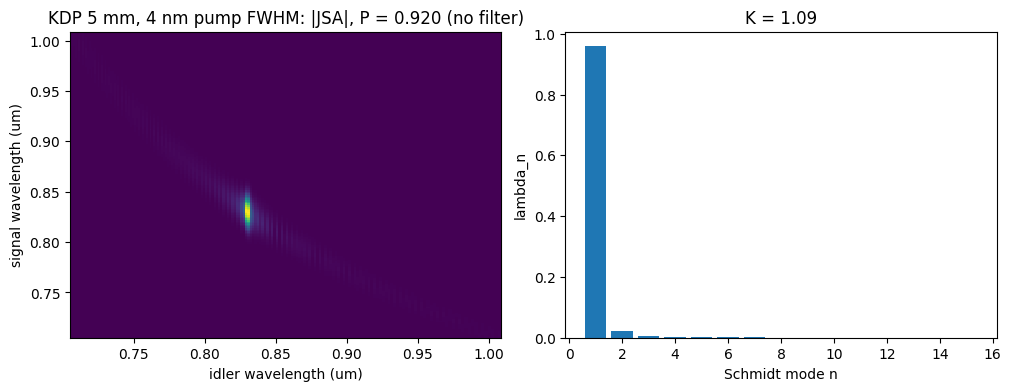

In [4]:
L = 5e-3
fw = fwhm_omega_from_fwhm_wavelength(0.004, 0.415)
w0 = lambda_um_to_omega(0.83)
win = 4e14
ax_ = np.linspace(w0 - win, w0 + win, 180)
res = build_jsa(ax_, ax_, wp, th, CFG_KDP, KDP["x"], KDP["y"], KDP["z"], L, fw)
lam_ax = 2*np.pi*C_LIGHT/ax_*1e6
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
a1.pcolormesh(lam_ax, lam_ax, np.abs(res.f), shading="auto", rasterized=True)
a1.set_xlabel("idler wavelength (um)"); a1.set_ylabel("signal wavelength (um)")
a1.set_title(f"KDP 5 mm, 4 nm pump FWHM: |JSA|, P = {res.purity:.3f} (no filter)")
a2.bar(range(1, 16), res.schmidt_lambdas[:15])
a2.set_xlabel("Schmidt mode n"); a2.set_ylabel("lambda_n"); a2.set_title(f"K = {res.schmidt_number:.2f}")
plt.show()

## Milestone 2 — KTP type-II EPM, König & Wong (2004) / Laudenbach et al. (2017)

x-axis propagation (theta = 90 deg in the x–z plane), 791 nm (o) →
2×1582 nm (o+e). n_y is König & Wong's own Eq. (3) fit (sourced from the
paper, `papers/09.`); n_z is Fradkin et al. (1999), which König & Wong
adopted unmodified. Reference numbers: Laudenbach et al. 2017, Fig. 1.

In [5]:
GD_p, GD_s, GD_i = phase_matched_group_delays_ps_per_mm(
    0.791, 1.582, 1.582, np.pi/2, "xz", "o", "o", "e", KTP["x"], KTP["y"], KTP["z"])
D = -(GD_p - GD_s) / (GD_p - GD_i)
tpm = theta_pm_deg(GD_p, GD_s, GD_i)
Lam = find_qpm_period_um(np.pi/2, 0.791, 1.582, 1.582, "xz", "o", "o", "e",
                          KTP["x"], KTP["y"], KTP["z"])
print(f"{'quantity':>22} {'computed':>10} {'literature':>10}")
for name, c, lit in (("GD_p (ps/mm)", GD_p, 6.027), ("GD_s (ps/mm)", GD_s, 5.880),
                     ("GD_i (ps/mm)", GD_i, 6.175), ("D", D, 0.993),
                     ("QPM period (um)", Lam, 46.1)):
    print(f"{name:>22} {c:>10.4f} {lit:>10.3f}   ({abs(c-lit)/lit:.2%})")
print(f"theta_PM = {tpm:.1f} deg (= 45 deg mod 180: symmetric GVM / EPM locus)")

              quantity   computed literature
          GD_p (ps/mm)     6.0309      6.027   (0.06%)
          GD_s (ps/mm)     5.8833      5.880   (0.06%)
          GD_i (ps/mm)     6.1783      6.175   (0.05%)
                     D     1.0007      0.993   (0.77%)
       QPM period (um)    46.1458     46.100   (0.10%)
theta_PM = -135.0 deg (= 45 deg mod 180: symmetric GVM / EPM locus)


**History note.** This milestone was first closed as *partial*: with a
Kato–Takaoka n_y proxy the pump group delay was ~2.9% off and the GVM
regime misclassified as asymmetric. Locating König & Wong's paper
(papers/09.) provided their own n_y coefficients and closed the gap to
<1% on all five quantities — an instructive example of how sensitive GVM
classification is to the *dispersion slope* (not absolute index) of a
Sellmeier fit. Full account: PROGRESS.md, `bibojsa/materials/ktp.py`.